# C. Dampak Kejadian pada Titik Ramai Grid 500 m

**Data:** `presence_cell500m_daily.csv` (JogjaPulse) dan `data/external/kalender_kejadian.csv`
**Penanggung jawab:** Anggota C

## Pertanyaan riset

1. Di mana titik ramai DIY pada masa normal (awal Desember 2021)?
2. Bagaimana kepadatan titik ramai itu berubah saat Nataru, gelombang Omicron, dan Ramadan 2022?
3. Apakah muncul titik ramai baru yang tidak ramai pada masa normal?

## Setup

In [1]:
from pathlib import Path
import sys

sys.path.insert(0, str(Path.cwd().parent / "src"))

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch
from pyproj import Transformer
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from shapely.geometry import box

from ritme import io, maps, style

style.apply()

## Metode

| Masalah | Penanganan |
|---|---|
| Jumlah perangkat turun dari ≈87 ribu/hari (Des) ke ≈9 ribu/hari (Apr), dengan lompatan 1 Jan dan 16 Feb | Semua perbandingan memakai **pangsa harian** terhadap panel sel tetap (bagian 2). Setiap kejadian dibandingkan dengan **baseline dekat** dengan hari dalam pekan yang dicocokkan. |
| Jumlah sel yang lolos supresi berubah antarbulan | Penyebut pangsa memakai **panel sel tetap**, bukan semua sel yang kebetulan terbit hari itu. |
| Sel-sel paling ramai ternyata **artefak lokasi** (lihat bagian 1) | Sel artefak dikeluarkan sebelum pangsa dihitung ulang dan titik ramai dicari. |
| Baris dengan < 5 perangkat dihapus | Untuk sel panel, hari yang hilang diisi 2,5 perangkat (nilai tengah 0–4, sama dengan notebook A). |
| Tanggal anomali data (1 Jan, 16 Feb, 8 Mar) | Dibuang dari semua perhitungan. |

Jendela kejadian (sumber di kalender kejadian):

| Kejadian | Jendela | Baseline | Hari yang dibuang |
|---|---|---|---|
| Nataru | 24 Des 2021 – 2 Jan 2022 (Inmendagri 66/2021) | 1–19 Des 2021 | 1 Jan (anomali) |
| Omicron | 8 Feb – 21 Mar 2022 (PPKM Level 3 lalu Level 4 di DIY) | 10 Jan – 6 Feb 2022 (PPKM Level 2) | 1 Feb, 16 Feb, 28 Feb, 3 Mar, 8 Mar |
| Ramadan | 3–30 Apr 2022 (sidang isbat Kemenag) | 22 Mar – 1 Apr 2022 (PPKM Level 2, sesudah Level 4) | 15 Apr, 29 Apr |

Libur nasional di dalam jendela dibuang supaya efek libur tidak tercampur dengan efek kejadian (kecuali Natal, yang memang bagian dari Nataru).

In [2]:
ANOMALI_DATA = pd.to_datetime(["2022-01-01", "2022-02-16", "2022-03-08"])
ISIAN_TERSUPRESI = 2.5
N_BOOT = 2000
PERSENTIL_TITIK_RAMAI = 0.90
AMBANG_ARTEFAK = 8
BASELINE_TITIK_RAMAI = ("2021-12-01", "2021-12-19")

KEJADIAN = pd.DataFrame(
    [
        ("Nataru", "2021-12-24", "2022-01-02", "2021-12-01", "2021-12-19"),
        ("Omicron", "2022-02-08", "2022-03-21", "2022-01-10", "2022-02-06"),
        ("Ramadan", "2022-04-03", "2022-04-30", "2022-03-22", "2022-04-01"),
    ],
    columns=["kejadian", "mulai", "selesai", "base_mulai", "base_selesai"],
)
WARNA_KEJADIAN = dict(zip(KEJADIAN["kejadian"], style.CATEGORICAL[:3]))

kalender = io.load_event_calendar()
LIBUR = kalender.loc[kalender["kategori"].isin(["libur_nasional", "cuti_bersama"]), "tanggal_mulai"]
DIBUANG = ANOMALI_DATA.union(LIBUR[LIBUR != "2021-12-25"])

In [3]:
mentah = io.load_presence_cell_daily()
mentah = mentah[~mentah["date"].isin(ANOMALI_DATA)].assign(
    i=lambda d: d["x_min_utm"] // 500,
    j=lambda d: d["y_min_utm"] // 500,
)
harian = mentah.groupby("date").agg(sel_terbit=("cell_id", "nunique"), total_perangkat=("n_maids", "sum"))
harian.resample("MS").mean().round(0)

,sel_terbit,total_perangkat
date,,
2021-12-01,1564.0,104550.0
2022-01-01,1785.0,82896.0
2022-02-01,1912.0,78340.0
2022-03-01,525.0,11732.0
2022-04-01,372.0,8638.0


Jumlah sel yang lolos supresi per hari turun dari ±1.600 (Desember) ke ±370 (April). Di Maret–April hanya sel yang cukup ramai yang masih terbaca, jadi analisis per sel di dua bulan itu terbatas pada titik ramai.

## 1. Artefak lokasi di grid 500 m

Saat sel diurutkan menurut pangsa, sel teratas bukan pusat keramaian yang dikenal. Sel nomor 1 tepat berada di titik koordinat bulat (110,30° BT; 7,80° LS). Banyak sel lain berjajar pada pola kisi berjarak ±2,5 km, dengan pangsa puluhan sampai ratusan kali lipat sel tetangganya. Pola seperti ini cocok dengan perangkat yang lokasinya tidak presisi lalu ditarik ke satu titik acuan. README dataset tidak membahasnya.

Aturan penandaan artefak (dihitung pada baseline 1–19 Des):
- sel yang memuat titik koordinat bulat kelipatan 0,1°, **atau**
- sel di 10% pangsa teratas yang pangsanya lebih dari 8× **median** 8 sel tetangganya (tetangga yang tersupresi dihitung 0).

Median tetangga dipakai, bukan maksimum, supaya kawasan ramai yang memang padat (misalnya Malioboro) tidak ikut terbuang: tetangganya juga ramai, jadi rasionya rendah.

In [4]:
def pangsa_harian(df):
    return df.assign(share=df["n_maids"] / df.groupby("date")["n_maids"].transform("sum"))


def ringkas_sel(df, mulai, selesai):
    jendela = df[df["date"].between(mulai, selesai)]
    n_hari = jendela["date"].nunique()
    return jendela.groupby("cell_id").agg(
        i=("i", "first"), j=("j", "first"),
        lon=("centroid_lon", "first"), lat=("centroid_lat", "first"),
        x=("x_min_utm", "first"), y=("y_min_utm", "first"),
        share=("share", "sum"), hari=("date", "nunique"),
    ).assign(share=lambda d: d["share"] / n_hari, prop_hari=lambda d: d["hari"] / n_hari)


def median_tetangga(sel):
    pangsa = sel.set_index(["i", "j"])["share"]
    geser = [(a, b) for a in (-1, 0, 1) for b in (-1, 0, 1) if (a, b) != (0, 0)]
    return np.array([np.median([pangsa.get((i + a, j + b), 0.0) for a, b in geser]) for i, j in zip(sel["i"], sel["j"])])


def sel_titik_bulat(sel):
    ke_utm = Transformer.from_crs(4326, 32749, always_xy=True)
    lon, lat = np.meshgrid(np.round(np.arange(109.9, 111.01, 0.1), 1), np.round(np.arange(-8.4, -7.39, 0.1), 1))
    x, y = ke_utm.transform(lon.ravel(), lat.ravel())
    titik = set(zip((np.asarray(x) // 500).astype(int), (np.asarray(y) // 500).astype(int)))
    return np.array([(i, j) in titik for i, j in zip(sel["i"], sel["j"])])


def tandai_artefak(sel, ambang):
    rasio = sel["share"] / median_tetangga(sel)
    kandidat = sel["share"] >= sel["share"].quantile(0.9)
    return sel.assign(rasio_tetangga=rasio, titik_bulat=sel_titik_bulat(sel)).assign(
        artefak=lambda d: d["titik_bulat"] | (kandidat & (d["rasio_tetangga"] > ambang))
    )


sel_awal = tandai_artefak(ringkas_sel(pangsa_harian(mentah), *BASELINE_TITIK_RAMAI), AMBANG_ARTEFAK)
sel_awal = sel_awal.sort_values("share", ascending=False).assign(peringkat=lambda d: np.arange(1, len(d) + 1))
sel_awal.head(12)[["peringkat", "lon", "lat", "share", "rasio_tetangga", "titik_bulat", "artefak"]].round(4)

,peringkat,lon,lat,share,rasio_tetangga,titik_bulat,artefak
cell_id,,,,,,,
E845_N18275,1,110.2994,-7.8000,0.0407,6426.1415,True,True
E845_N18297,2,110.2995,-7.7005,0.0356,inf,True,True
E867_N18297,3,110.3993,-7.7006,0.0207,697.4195,True,True
E859_N18274,4,110.3628,-7.8046,0.0118,23.0059,False,True
E867_N18275,5,110.3991,-7.8001,0.0116,94.1686,True,True
E872_N18313,6,110.4220,-7.6283,0.0108,inf,False,True
E865_N18299,7,110.3902,-7.6916,0.0104,1494.4892,False,True
E865_N18288,8,110.3901,-7.7413,0.0086,30.5742,False,True
E870_N18274,9,110.4127,-7.8047,0.0084,26.7019,False,True


In [5]:
ringkas_artefak = pd.DataFrame(
    {
        ambang: {
            "sel_artefak": int(t["artefak"].sum()),
            "pangsa_artefak_baseline": round(t.loc[t["artefak"], "share"].sum(), 3),
        }
        for ambang in [5, 8, 15]
        for t in [tandai_artefak(sel_awal.drop(columns=["rasio_tetangga", "titik_bulat", "artefak"]), ambang)]
    }
).T.rename_axis("ambang_rasio")
ringkas_artefak

,sel_artefak,pangsa_artefak_baseline
ambang_rasio,,
5,281.0,0.688
8,264.0,0.658
15,233.0,0.605


In [6]:
ID_ARTEFAK = set(sel_awal.index[sel_awal["artefak"]])
pangsa_artefak_bulanan = (
    pangsa_harian(mentah)
    .assign(artefak=lambda d: d["cell_id"].isin(ID_ARTEFAK), bulan=lambda d: d["date"].dt.strftime("%Y-%m"))
    .query("artefak")
    .groupby(["bulan", "date"])["share"].sum()
    .groupby("bulan").mean()
    .round(3)
    .rename("pangsa_harian_sel_artefak")
)
pangsa_artefak_bulanan.to_frame()

,pangsa_harian_sel_artefak
bulan,
2021-12,0.655
2022-01,0.517
2022-02,0.399
2022-03,0.574
2022-04,0.478


Sel artefak memegang 40–66% pangsa harian, dan porsinya naik-turun antarbulan mengikuti perubahan sampel data, bukan perilaku orang. Kalau sel artefak tidak dikeluarkan, naik-turunnya porsi artefak akan menggeser pangsa semua sel lain dan terbaca seolah-olah dampak Omicron atau Ramadan.

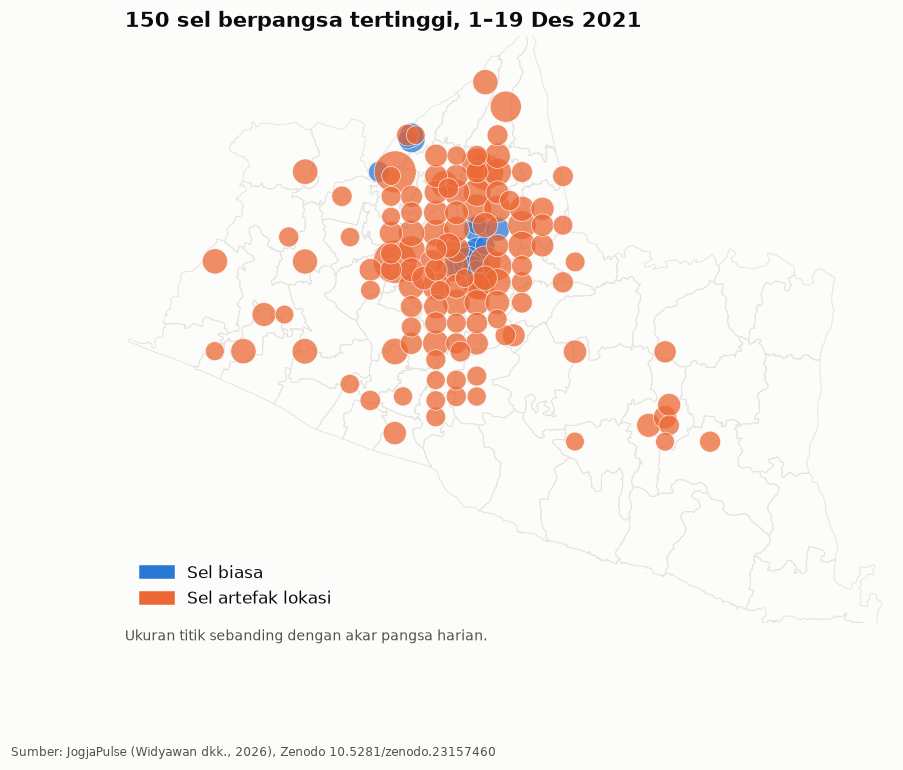

In [7]:
batas = maps.load_kapanewon_boundaries()


def poligon_sel(sel):
    geom = [box(x, y, x + 500, y + 500) for x, y in zip(sel["x"], sel["y"])]
    return gpd.GeoDataFrame(sel, geometry=geom, crs=32749).to_crs(4326)


def peta_dasar(ax, xlim=(110.0, 110.85), ylim=(-8.2, -7.55)):
    batas.plot(ax=ax, facecolor="none", edgecolor=style.GRID, linewidth=0.6)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.set_xlabel("")
    ax.set_ylabel("")
    for spine in ax.spines.values():
        spine.set_visible(False)


fig, ax = plt.subplots(figsize=(9, 7.5))
peta_dasar(ax)
teratas = poligon_sel(sel_awal.head(150))
skala = 4000 * teratas["share"] ** 0.5
for artefak, warna in [(False, style.CATEGORICAL[0]), (True, style.CATEGORICAL[1])]:
    bagian = teratas[teratas["artefak"] == artefak]
    ax.scatter(bagian["lon"], bagian["lat"], s=skala[bagian.index], color=warna, alpha=0.75, edgecolor="white", linewidth=0.5)
ax.legend(
    handles=[Patch(color=style.CATEGORICAL[0], label="Sel biasa"), Patch(color=style.CATEGORICAL[1], label="Sel artefak lokasi")],
    loc="lower left",
)
ax.set_title("150 sel berpangsa tertinggi, 1–19 Des 2021")
ax.text(0, -0.03, "Ukuran titik sebanding dengan akar pangsa harian.", transform=ax.transAxes, fontsize=9, color=style.TEXT_SECONDARY)
style.add_source(fig)
style.save(fig, "C1_artefak_lokasi");

## 2. Panel sel tetap

Masalah kedua: jumlah sel yang lolos supresi per hari berubah dari ±1.600 (Desember) ke ±1.900 (Februari) lalu ±370 (April). Kalau pangsa dihitung terhadap semua sel yang terbit hari itu, pangsa titik ramai ikut naik-turun hanya karena sel-sel kecil muncul dan hilang dari data.

Karena itu penyebut pangsa memakai **panel sel tetap**: sel bukan artefak yang terbit pada sedikitnya 70% hari di seluruh periode. Pada hari sel panel tersupresi, nilainya diisi 2,5 perangkat. Pangsa sel = `n_maids` sel ÷ jumlah `n_maids` semua sel panel pada hari itu. Penjumlahan ini hanya dipakai sebagai penyebut, bukan sebagai jumlah orang.

In [8]:
PROP_HARI_PANEL = 0.70
bersih = mentah[~mentah["cell_id"].isin(ID_ARTEFAK)]
info_sel = bersih.groupby("cell_id").agg(
    i=("i", "first"), j=("j", "first"), lon=("centroid_lon", "first"), lat=("centroid_lat", "first"),
    x=("x_min_utm", "first"), y=("y_min_utm", "first"),
)


def susun_panel(data, min_hari=PROP_HARI_PANEL, isian=ISIAN_TERSUPRESI):
    tanggal = np.sort(data["date"].unique())
    terisi = data.groupby("cell_id")["date"].nunique() / len(tanggal)
    n = (
        data.pivot_table(index="date", columns="cell_id", values="n_maids")
        .reindex(index=tanggal, columns=terisi.index[terisi >= min_hari])
        .fillna(isian)
    )
    return n.div(n.sum(axis=1), axis=0)


panel = susun_panel(bersih)
print(f"Panel: {panel.shape[1]} sel, {panel.shape[0]} hari")

Panel: 295 sel, 148 hari


## 3. Titik ramai dan kawasan pada masa normal

Titik ramai = sel panel dengan rata-rata pangsa 1–19 Des 2021 di 10% teratas. Titik ramai yang bersebelahan (termasuk diagonal) digabung menjadi satu **kawasan**, lalu diberi nama kapanewon tempat sebagian besar selnya berada. Kawasan yang mencakup tiga kapanewon atau lebih di Kota Yogyakarta dinamai "Pusat Kota Yogyakarta".

In [9]:
lookup_kapanewon = batas[["kapanewon_code", "namobj", "geometry"]]


def rata_periode(panel, mulai, selesai, dibuang=DIBUANG):
    jendela = panel.loc[mulai:selesai]
    return jendela[~jendela.index.isin(dibuang)].mean()


def cari_titik_ramai(pangsa_rata, persentil=PERSENTIL_TITIK_RAMAI):
    terpilih = pangsa_rata[pangsa_rata >= pangsa_rata.quantile(persentil)]
    return info_sel.loc[terpilih.index].assign(share=terpilih)


def beri_kawasan(titik):
    i, j = titik["i"].to_numpy(), titik["j"].to_numpy()
    tetangga = (np.abs(i[:, None] - i[None]) <= 1) & (np.abs(j[:, None] - j[None]) <= 1)
    _, label = connected_components(coo_matrix(tetangga), directed=False)
    return titik.assign(kawasan_id=label)


def nama_kawasan(titik):
    titik_geo = gpd.GeoDataFrame(titik, geometry=gpd.points_from_xy(titik["lon"], titik["lat"]), crs=4326)
    letak = gpd.sjoin(titik_geo, lookup_kapanewon, how="left", predicate="within")
    utama = letak.groupby("kawasan_id")["namobj"].agg(lambda s: s.value_counts().index[0].title())
    ragam = letak.groupby("kawasan_id")["namobj"].nunique()
    kota = letak["kapanewon_code"].str.startswith("34.71").groupby(letak["kawasan_id"]).any()
    label = {}
    for k in titik.groupby("kawasan_id")["share"].sum().sort_values(ascending=False).index:
        dasar = "Pusat Kota Yogyakarta" if ragam[k] >= 3 and kota[k] else utama[k]
        sudah = sum(v == dasar or v.startswith(dasar + " ") for v in label.values())
        label[k] = dasar if sudah == 0 else f"{dasar} {sudah + 1}"
    return titik.assign(kawasan=titik["kawasan_id"].map(label))


pangsa_baseline = rata_periode(panel, *BASELINE_TITIK_RAMAI)
titik_ramai = nama_kawasan(beri_kawasan(cari_titik_ramai(pangsa_baseline)))
kawasan = (
    titik_ramai.groupby("kawasan")
    .agg(jumlah_sel=("share", "size"), pangsa_baseline=("share", "sum"), lon=("lon", "mean"), lat=("lat", "mean"))
    .sort_values("pangsa_baseline", ascending=False)
)
print(f"{len(titik_ramai)} titik ramai dalam {len(kawasan)} kawasan")
kawasan.round(4)

30 titik ramai dalam 8 kawasan


,jumlah_sel,pangsa_baseline,lon,lat
kawasan,,,,
Pusat Kota Yogyakarta,16,0.3130,110.3801,-7.8007
Depok,6,0.0783,110.3909,-7.7647
Depok 2,2,0.0332,110.4150,-7.7640
Gondokusuman,2,0.0319,110.3901,-7.7843
Tempel,1,0.0238,110.3177,-7.6598
Depok 3,1,0.0104,110.3991,-7.7820
Umbulharjo,1,0.0093,110.3945,-7.8318
Danurejan,1,0.0073,110.3674,-7.7910


## 4. Dampak kejadian per kawasan

Pangsa kawasan = jumlah pangsa sel-selnya di panel. Ukuran dampak per hari dalam jendela kejadian adalah `log(pangsa hari itu ÷ rata-rata pangsa baseline pada hari dalam pekan yang sama)`. Rata-rata log rasio semua hari jendela diubah menjadi persentase perubahan. Interval kepercayaan 95% dihitung dengan bootstrap terhadap hari (2.000 ulangan).

Karena pangsa panel selalu berjumlah 1, kenaikan pangsa titik ramai berarti kepadatan bergeser **ke** titik ramai dari sel lain, dan penurunan berarti kepadatan menyebar ke luar titik ramai.

In [10]:
def pangsa_per_kawasan(panel, titik):
    pk = panel[titik.index].T.groupby(titik["kawasan"]).sum().T
    return pk.assign(**{"Semua titik ramai": panel[titik.index].sum(axis=1)})


def efek_kejadian(pangsa_kawasan, kejadian, dibuang=DIBUANG, seed=0):
    pk = pangsa_kawasan[~pangsa_kawasan.index.isin(dibuang)]
    rng = np.random.default_rng(seed)
    hasil = []
    for k in kejadian.itertuples():
        base = pk.loc[k.base_mulai:k.base_selesai]
        acuan = base.groupby(base.index.day_of_week).mean()
        jendela = pk.loc[k.mulai:k.selesai]
        log_rasio = np.log(jendela / acuan.reindex(jendela.index.day_of_week).to_numpy())
        boot = rng.integers(0, len(log_rasio), (N_BOOT, len(log_rasio)))
        for nama in log_rasio.columns:
            nilai = log_rasio[nama].to_numpy()
            rata = nilai[boot].mean(axis=1)
            hasil.append({
                "kejadian": k.kejadian, "kawasan": nama, "n_hari": len(nilai),
                "perubahan_pct": 100 * (np.exp(nilai.mean()) - 1),
                "ci_bawah": 100 * (np.exp(np.percentile(rata, 2.5)) - 1),
                "ci_atas": 100 * (np.exp(np.percentile(rata, 97.5)) - 1),
            })
    return pd.DataFrame(hasil)


pangsa_kawasan = pangsa_per_kawasan(panel, titik_ramai)
efek = efek_kejadian(pangsa_kawasan, KEJADIAN)
URUT_KAWASAN = ["Semua titik ramai", *kawasan.index]
efek.pivot(index="kawasan", columns="kejadian", values="perubahan_pct").loc[URUT_KAWASAN].round(1)

kejadian,Nataru,Omicron,Ramadan
kawasan,,,
Semua titik ramai,-4.7,-34.6,23.1
Pusat Kota Yogyakarta,-3.5,-34.8,20.1
Depok,-9.7,-39.7,32.2
Depok 2,-18.7,-29.0,40.3
Gondokusuman,-7.0,1.8,23.6
Tempel,-34.1,-92.3,58.9
Depok 3,9.1,-36.0,-39.4
Umbulharjo,-15.7,-65.9,23.3
Danurejan,-8.3,26.0,1.0


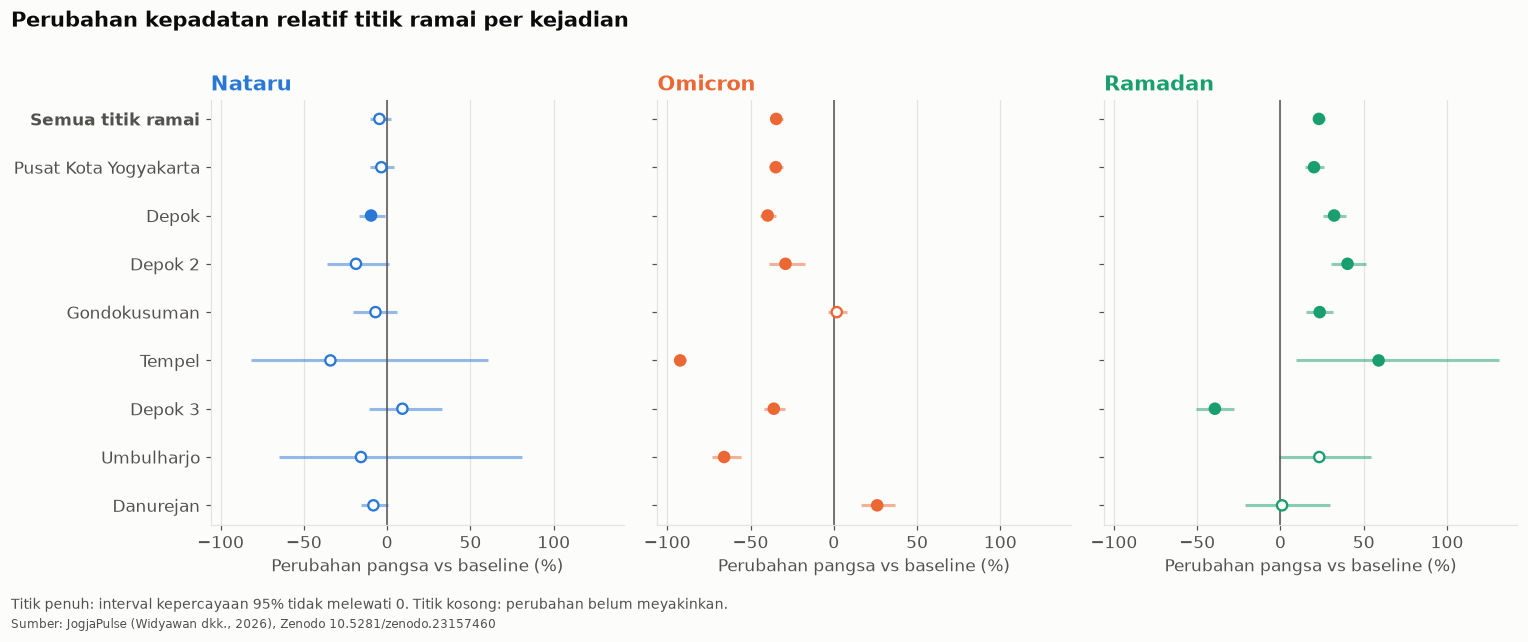

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 0.42 * len(URUT_KAWASAN) + 1.8), sharey=True, sharex=True)
posisi = {k: len(URUT_KAWASAN) - 1 - n for n, k in enumerate(URUT_KAWASAN)}
for ax, nama in zip(axes, KEJADIAN["kejadian"]):
    d = efek[efek["kejadian"] == nama]
    y = d["kawasan"].map(posisi)
    meyakinkan = (d["ci_bawah"] > 0) | (d["ci_atas"] < 0)
    ax.hlines(y, d["ci_bawah"], d["ci_atas"], color=WARNA_KEJADIAN[nama], linewidth=2, alpha=0.5)
    ax.scatter(d["perubahan_pct"], y, color=np.where(meyakinkan, WARNA_KEJADIAN[nama], style.SURFACE),
               edgecolor=WARNA_KEJADIAN[nama], s=45, zorder=3, linewidth=1.5)
    ax.axvline(0, color=style.TEXT_SECONDARY, linewidth=1)
    ax.set_title(nama, color=WARNA_KEJADIAN[nama])
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Perubahan pangsa vs baseline (%)")
axes[0].set_yticks(list(posisi.values()))
axes[0].set_yticklabels(list(posisi))
axes[0].get_yticklabels()[0].set_fontweight("bold")
fig.suptitle("Perubahan kepadatan relatif titik ramai per kejadian", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.text(0.01, 0.005, "Titik penuh: interval kepercayaan 95% tidak melewati 0. Titik kosong: perubahan belum meyakinkan.",
         fontsize=9, color=style.TEXT_SECONDARY)
fig.tight_layout(rect=(0, 0.03, 1, 0.97))
style.add_source(fig)
style.save(fig, "C3_dotplot_kawasan");

## 5. Perjalanan waktu

Indeks = pangsa harian kawasan dibagi rata-rata pangsanya pada 1–19 Des (1 = sama dengan masa normal), ditampilkan sebagai rata-rata bergerak 7 hari. Area berwarna menandai jendela tiga kejadian.

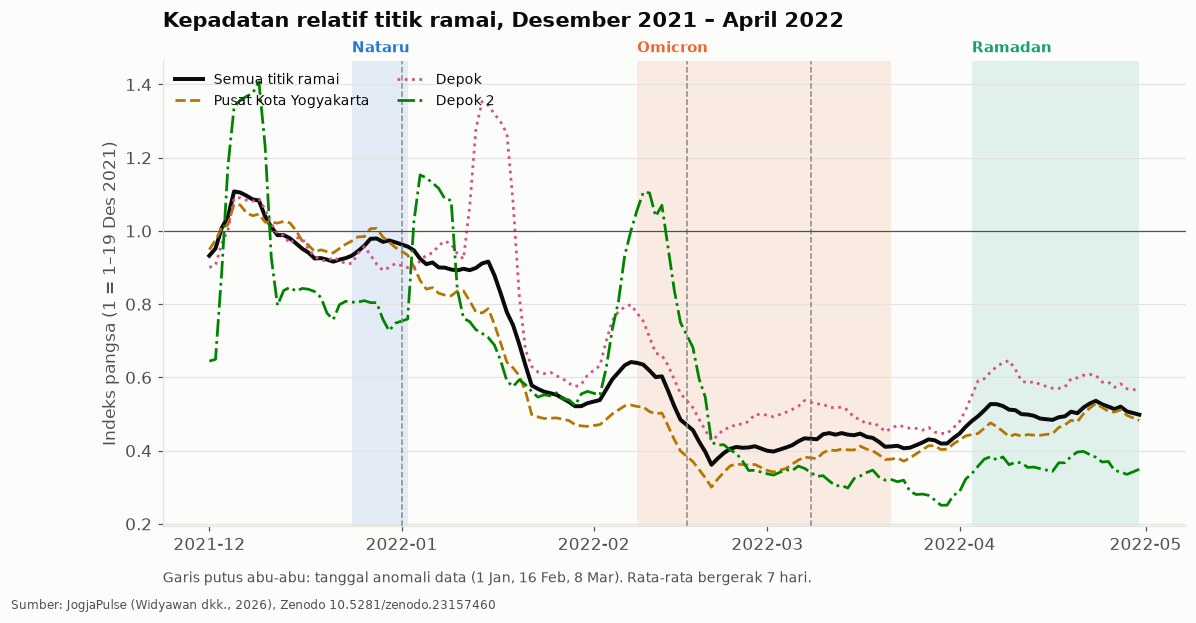

In [12]:
TAMPIL_TS = ["Semua titik ramai", *kawasan.index[:3]]
acuan_des = pangsa_kawasan.loc[BASELINE_TITIK_RAMAI[0]:BASELINE_TITIK_RAMAI[1]].mean()
indeks = (pangsa_kawasan[~pangsa_kawasan.index.isin(DIBUANG)] / acuan_des).rolling(7, min_periods=4, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 5.5))
for k in KEJADIAN.itertuples():
    ax.axvspan(pd.Timestamp(k.mulai), pd.Timestamp(k.selesai), color=WARNA_KEJADIAN[k.kejadian], alpha=0.12, linewidth=0)
    ax.text(pd.Timestamp(k.mulai), 1.01, k.kejadian, transform=ax.get_xaxis_transform(), color=WARNA_KEJADIAN[k.kejadian],
            fontsize=10, fontweight="bold", va="bottom")
for nama, gaya, warna in zip(TAMPIL_TS, ["-", "--", ":", "-."], [style.TEXT_PRIMARY, *style.CATEGORICAL[3:6]]):
    ax.plot(indeks.index, indeks[nama], linestyle=gaya, color=warna, linewidth=2.6 if nama == "Semua titik ramai" else 1.8, label=nama)
style.mark_events(ax, kalender[kalender["kategori"] == "anomali_data"], label=False)
ax.axhline(1, color=style.TEXT_SECONDARY, linewidth=0.8)
ax.set_ylabel("Indeks pangsa (1 = 1–19 Des 2021)")
ax.set_title("Kepadatan relatif titik ramai, Desember 2021 – April 2022", pad=22)
ax.legend(loc="upper left", ncol=2, fontsize=9)
ax.text(0, -0.12, "Garis putus abu-abu: tanggal anomali data (1 Jan, 16 Feb, 8 Mar). Rata-rata bergerak 7 hari.",
        transform=ax.transAxes, fontsize=9, color=style.TEXT_SECONDARY)
style.add_source(fig)
style.save(fig, "C2_timeseries_kawasan");

## 6. Peta perubahan per sel

Perubahan per sel panel = log rasio rata-rata pangsa jendela kejadian terhadap baseline-nya. Peta diperbesar ke area perkotaan Yogyakarta, tempat sebagian besar sel panel berada.

In [13]:
def perubahan_sel(panel, k):
    a = rata_periode(panel, k.base_mulai, k.base_selesai)
    b = rata_periode(panel, k.mulai, k.selesai)
    return info_sel.loc[panel.columns].assign(log_rasio=np.log(b / a))


per_sel = {k.kejadian: perubahan_sel(panel, k) for k in KEJADIAN.itertuples()}
pd.DataFrame({
    nama: {"naik_lebih_25pct": int((d["log_rasio"] > np.log(1.25)).sum()), "turun_lebih_20pct": int((d["log_rasio"] < np.log(0.8)).sum())}
    for nama, d in per_sel.items()
}).T

,naik_lebih_25pct,turun_lebih_20pct
Nataru,61,55
Omicron,122,63
Ramadan,27,130


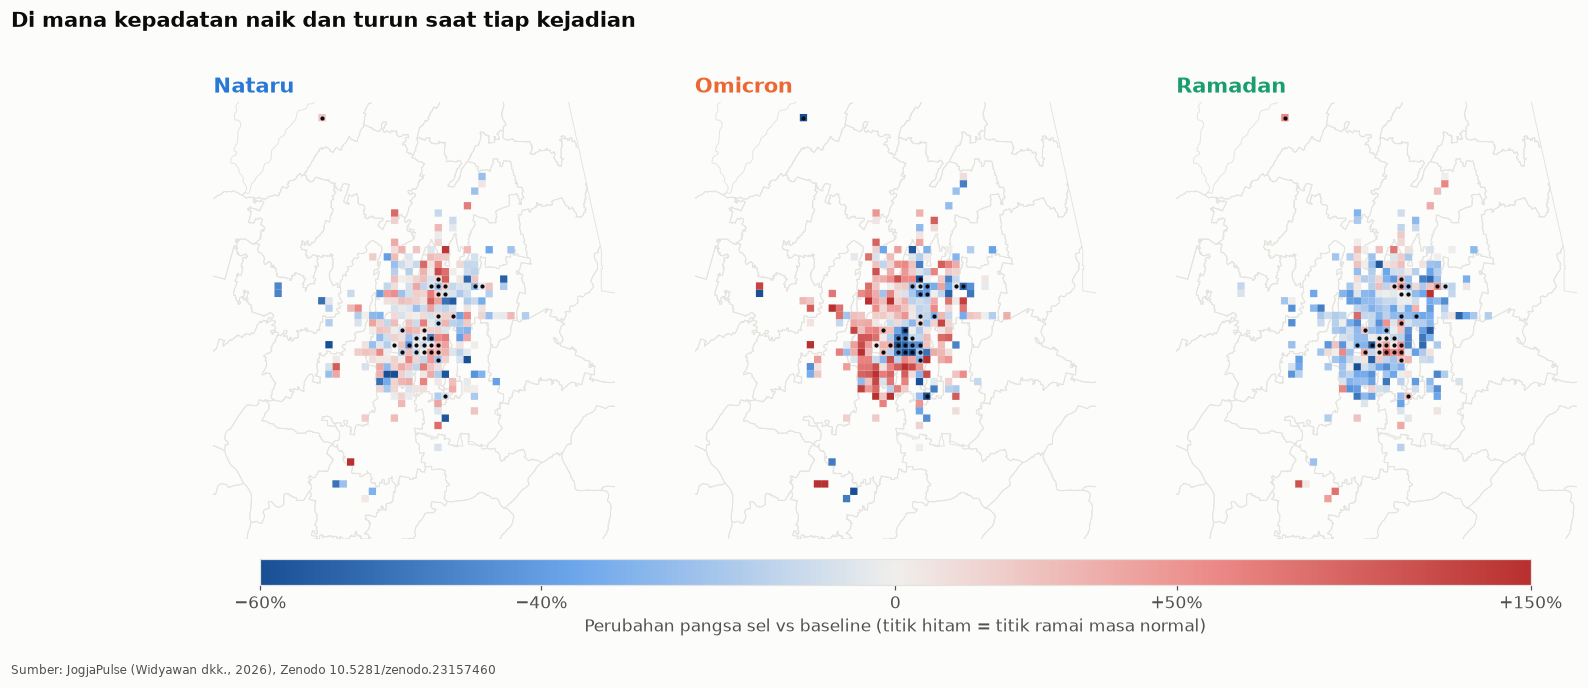

In [14]:
BATAS_WARNA = np.log(2.5)
norma = TwoSlopeNorm(vmin=-BATAS_WARNA, vcenter=0, vmax=BATAS_WARNA)
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, (nama, d) in zip(axes, per_sel.items()):
    peta_dasar(ax, xlim=(110.25, 110.5), ylim=(-7.92, -7.65))
    g = poligon_sel(d)
    g.plot(ax=ax, column=g["log_rasio"].clip(-BATAS_WARNA, BATAS_WARNA), cmap=style.DIVERGING, norm=norma, linewidth=0)
    titik_ramai.plot.scatter(x="lon", y="lat", ax=ax, s=3, color=style.TEXT_PRIMARY)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(nama, color=WARNA_KEJADIAN[nama])
skala = plt.cm.ScalarMappable(norm=norma, cmap=style.DIVERGING)
cbar = fig.colorbar(skala, ax=axes, orientation="horizontal", fraction=0.05, pad=0.04, aspect=50)
cbar.set_ticks(np.log([0.4, 0.6, 1, 1.5, 2.5]))
cbar.set_ticklabels(["−60%", "−40%", "0", "+50%", "+150%"])
cbar.set_label("Perubahan pangsa sel vs baseline (titik hitam = titik ramai masa normal)")
fig.suptitle("Di mana kepadatan naik dan turun saat tiap kejadian", x=0.01, y=0.98, ha="left", fontweight="bold", fontsize=14)
style.add_source(fig)
style.save(fig, "C4_peta_perubahan");

## 7. Titik ramai baru

Aturan titik ramai yang sama (10% pangsa teratas di panel) diterapkan pada tiap jendela kejadian dan baseline-nya. Kesamaan dua himpunan diukur dengan indeks Jaccard: 1 berarti identik, 0 berarti tidak ada yang sama. Sel yang masuk 10% teratas di jendela kejadian tetapi tidak di baseline disebut titik ramai baru.

In [15]:
def bandingkan_titik_ramai(panel, k):
    a = cari_titik_ramai(rata_periode(panel, k.base_mulai, k.base_selesai)).index
    b = cari_titik_ramai(rata_periode(panel, k.mulai, k.selesai)).index
    return {"jaccard": len(a.intersection(b)) / len(a.union(b)), "baru": info_sel.loc[b.difference(a)]}


banding = {k.kejadian: bandingkan_titik_ramai(panel, k) for k in KEJADIAN.itertuples()}
baru_semua = pd.concat([b["baru"].assign(kejadian=n) for n, b in banding.items()])
baru_geo = gpd.sjoin(
    gpd.GeoDataFrame(baru_semua, geometry=gpd.points_from_xy(baru_semua["lon"], baru_semua["lat"]), crs=4326),
    lookup_kapanewon, how="left", predicate="within",
)
pd.DataFrame({
    n: {
        "jaccard": round(b["jaccard"], 2),
        "titik_baru": len(b["baru"]),
        "kapanewon": ", ".join(f"{k.title()} ({v})" for k, v in baru_geo.loc[baru_geo["kejadian"] == n, "namobj"].value_counts().items()),
    }
    for n, b in banding.items()
}).T

,jaccard,titik_baru,kapanewon
Nataru,0.82,3,"Kraton (1), Umbulharjo (1), Depok (1)"
Omicron,0.36,14,"Bantul (2), Danurejan (2), Gondokusuman (2), G..."
Ramadan,0.62,7,"Umbulharjo (2), Danurejan (1), Pakualaman (1),..."


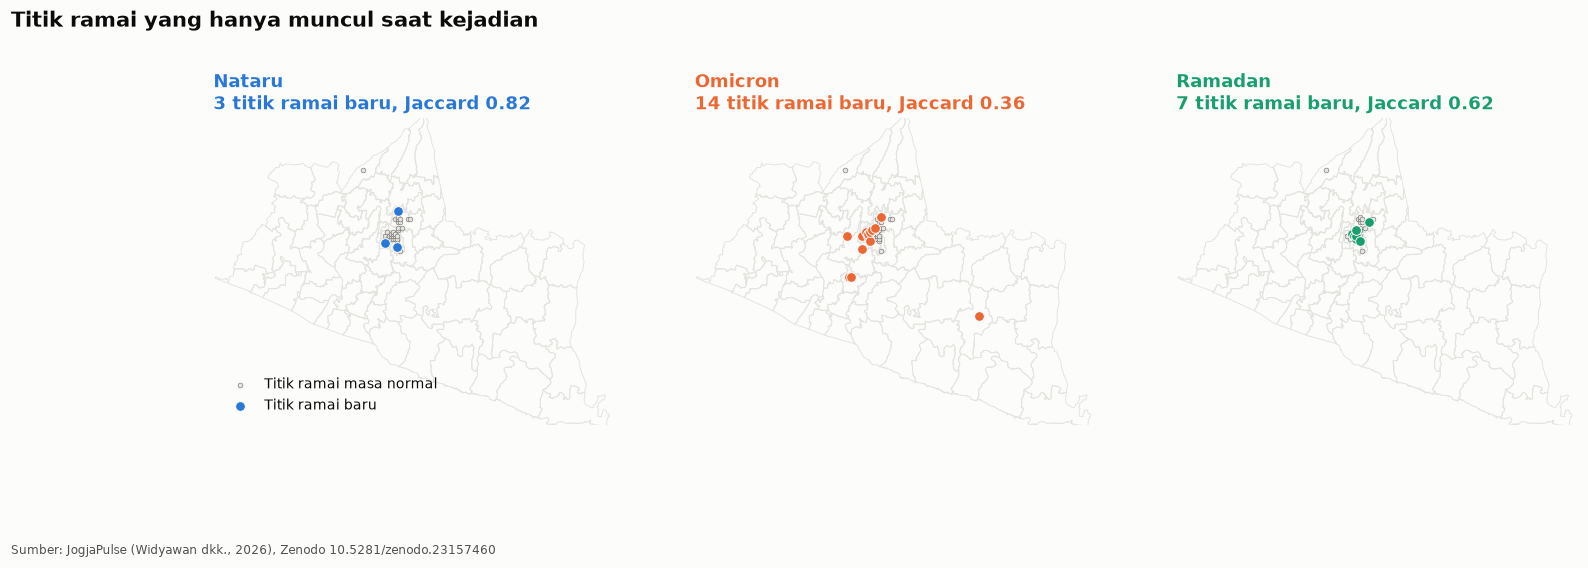

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.9))
for ax, nama in zip(axes, KEJADIAN["kejadian"]):
    peta_dasar(ax)
    ax.scatter(titik_ramai["lon"], titik_ramai["lat"], s=10, color=style.GRID, edgecolor=style.TEXT_SECONDARY, linewidth=0.3,
               label="Titik ramai masa normal")
    b = baru_geo[baru_geo["kejadian"] == nama]
    ax.scatter(b["lon"], b["lat"], s=40, color=WARNA_KEJADIAN[nama], edgecolor="white", linewidth=0.6, label="Titik ramai baru")
    ax.set_title(f"{nama}\n{len(b)} titik ramai baru, Jaccard {banding[nama]['jaccard']:.2f}", color=WARNA_KEJADIAN[nama], fontsize=12)
axes[0].legend(loc="lower left", fontsize=9)
fig.suptitle("Titik ramai yang hanya muncul saat kejadian", x=0.01, ha="left", fontweight="bold", fontsize=14)
style.add_source(fig)
style.save(fig, "C5_titik_ramai_baru");

## 8. Uji sensitivitas

Apakah kesimpulan berubah kalau
- (a) ambang artefak diganti 5 atau 15,
- (b) persentil titik ramai diganti 0,85 atau 0,95,
- (c) syarat panel diganti 60% atau 80% hari,
- (d) sel tersupresi diisi 0 atau 4,9,
- (e) jendela Omicron dipecah sebelum dan sesudah lompatan sampel 16 Feb,
- (f) baseline Ramadan diperpanjang ke 9 Mar – 1 Apr (mencakup PPKM Level 4)?

Yang dilaporkan adalah perubahan pangsa "Semua titik ramai" beserta interval kepercayaan 95%.

In [17]:
def efek_total(ambang=AMBANG_ARTEFAK, persentil=PERSENTIL_TITIK_RAMAI, min_hari=PROP_HARI_PANEL, isian=ISIAN_TERSUPRESI,
               kejadian=KEJADIAN):
    sel0 = tandai_artefak(ringkas_sel(pangsa_harian(mentah), *BASELINE_TITIK_RAMAI), ambang)
    p = susun_panel(mentah[~mentah["cell_id"].isin(sel0.index[sel0["artefak"]])], min_hari, isian)
    rata = rata_periode(p, *BASELINE_TITIK_RAMAI)
    titik = rata[rata >= rata.quantile(persentil)].index
    pk = p[titik].sum(axis=1).to_frame("Semua titik ramai")
    e = efek_kejadian(pk, kejadian).set_index("kejadian")
    return e.apply(lambda r: f"{r['perubahan_pct']:+.1f}% [{r['ci_bawah']:+.1f}, {r['ci_atas']:+.1f}]", axis=1)


pd.DataFrame({
    "Utama": efek_total(),
    "Ambang artefak 5": efek_total(ambang=5),
    "Ambang artefak 15": efek_total(ambang=15),
    "Persentil 0,85": efek_total(persentil=0.85),
    "Persentil 0,95": efek_total(persentil=0.95),
    "Panel 60% hari": efek_total(min_hari=0.6),
    "Panel 80% hari": efek_total(min_hari=0.8),
    "Isian tersupresi 0": efek_total(isian=0.0),
    "Isian tersupresi 4,9": efek_total(isian=4.9),
}).T

kejadian,Nataru,Omicron,Ramadan
Utama,"-4.7% [-10.5, +2.3]","-34.6% [-38.2, -30.4]","+23.1% [+19.3, +27.0]"
Ambang artefak 5,"-6.1% [-12.2, +1.7]","-38.9% [-41.8, -35.5]","+14.2% [+10.7, +18.0]"
Ambang artefak 15,"-3.1% [-9.5, +3.9]","-34.7% [-39.0, -29.6]","+24.4% [+18.6, +29.9]"
"Persentil 0,85","-4.4% [-8.7, +0.9]","-31.6% [-34.6, -28.0]","+16.9% [+13.3, +20.5]"
"Persentil 0,95","-5.3% [-13.0, +4.1]","-33.0% [-37.9, -27.8]","+31.2% [+25.7, +36.8]"
Panel 60% hari,"-5.1% [-10.0, +0.9]","-34.6% [-37.9, -30.8]","+14.8% [+11.3, +18.4]"
Panel 80% hari,"-6.0% [-12.4, +1.1]","-34.2% [-38.2, -29.5]","+23.5% [+18.9, +28.0]"
Isian tersupresi 0,"-4.7% [-10.5, +2.3]","-33.8% [-37.5, -29.7]","+25.9% [+21.3, +30.4]"
"Isian tersupresi 4,9","-4.6% [-10.4, +2.3]","-35.3% [-38.9, -31.1]","+20.8% [+17.3, +24.6]"


In [18]:
JENDELA_ALTERNATIF = pd.DataFrame([
    ("Omicron 8–15 Feb", "2022-02-08", "2022-02-15", "2022-01-10", "2022-02-06"),
    ("Omicron 17 Feb–21 Mar", "2022-02-17", "2022-03-21", "2022-01-10", "2022-02-06"),
    ("Ramadan, baseline 9 Mar–1 Apr", "2022-04-03", "2022-04-30", "2022-03-09", "2022-04-01"),
], columns=KEJADIAN.columns)
efek_total(kejadian=JENDELA_ALTERNATIF).rename("Semua titik ramai").to_frame()

,Semua titik ramai
kejadian,
Omicron 8–15 Feb,"-13.3% [-18.1, -8.6]"
Omicron 17 Feb–21 Mar,"-39.3% [-42.0, -36.7]"
"Ramadan, baseline 9 Mar–1 Apr","+20.0% [+16.9, +23.1]"


### Pembanding: hotspot Getis-Ord Gi*

Gi* mencari sel yang dikelilingi sel-sel berpangsa tinggi (klaster spasial), dihitung dari rata-rata pangsa panel 1–19 Des. Tetangga = 8 sel di sekitarnya. Kalau titik ramai versi persentil sebagian besar juga termasuk hotspot Gi* (p < 0,05, permutasi 999 kali), definisi titik ramai kita konsisten dengan metode statistik spasial.

In [19]:
import contextlib
import io as io_std
import warnings

from esda.getisord import G_Local
from libpysal.weights import DistanceBand

gi_sel = info_sel.loc[pangsa_baseline.index]
w = DistanceBand(np.c_[gi_sel["x"] + 250, gi_sel["y"] + 250], threshold=710, binary=True, silence_warnings=True)
with warnings.catch_warnings(), contextlib.redirect_stdout(io_std.StringIO()):
    warnings.simplefilter("ignore")
    gi = G_Local(pangsa_baseline.to_numpy(), w, star=1.0, permutations=999, seed=0, n_jobs=1)
hotspot_gi = gi_sel.index[(gi.Zs > 0) & (gi.p_sim < 0.05)]
irisan = titik_ramai.index.intersection(hotspot_gi)
print(f"Hotspot Gi*: {len(hotspot_gi)} sel. Titik ramai yang juga hotspot Gi*: {len(irisan)} dari {len(titik_ramai)} "
      f"({len(irisan) / len(titik_ramai):.0%}).")

Hotspot Gi*: 38 sel. Titik ramai yang juga hotspot Gi*: 20 dari 30 (67%).


## Simpan hasil

In [20]:
io.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
keluaran = io.PROCESSED_DIR / "C_dampak_kawasan.csv"
efek.merge(kawasan.reset_index(), on="kawasan", how="left").round(4).to_csv(keluaran, index=False)
titik_ramai.drop(columns=["kawasan_id"]).round(6).to_csv(io.PROCESSED_DIR / "C_titik_ramai.csv")
print("Disimpan:", keluaran.relative_to(io.ROOT))

Disimpan: data\processed\C_dampak_kawasan.csv


## Temuan

Analisis memakai panel 295 sel tetap (bukan artefak, terbit ≥ 70% hari) dari 1 Des 2021 sampai 30 Apr 2022, tanpa tanggal anomali data. Angka dalam kurung adalah interval kepercayaan 95%.

### 1. Dua pertiga pangsa grid 500 m berasal dari artefak lokasi

- 264 sel ditandai artefak. Sel-sel ini memegang 66% pangsa harian pada 1–19 Des, dan 40–66% per bulan sepanjang periode.
- Sel nomor 1 tepat berada di titik koordinat bulat 110,30° BT; 7,80° LS. Banyak sel artefak lain berjajar pada pola kisi berjarak ±2,5 km (peta C1).
- Kalau sel artefak tidak dikeluarkan, sel di kawasan Malioboro bahkan tidak masuk 150 sel teratas. Temuan ini relevan untuk bagian keterbatasan data (E).

### 2. Titik ramai masa normal terpusat di Kota Yogyakarta dan Depok

- Ada 30 titik ramai dalam 8 kawasan. Pusat Kota Yogyakarta (16 sel) memegang 31% pangsa panel, dan Depok (6 sel) 8%.
- 67% titik ramai juga merupakan hotspot Getis-Ord Gi*, jadi definisi berbasis persentil konsisten dengan klaster spasial.

### 3. Nataru tidak menggeser titik ramai secara meyakinkan

- Pangsa semua titik ramai berubah −4,7% (−10,5 sampai +2,3). Intervalnya melewati 0, dan hasil ini sama di semua uji sensitivitas.
- Susunan titik ramai hampir tidak berubah (Jaccard 0,82, hanya 3 titik baru).
- Larangan perayaan tahun baru dan penutupan alun-alun (Inmendagri 66/2021) sejalan dengan tidak adanya lonjakan di titik ramai. Data ini tidak bisa menguji hubungan sebab-akibatnya.

### 4. Saat Omicron, kepadatan menyebar ke luar titik ramai, tetapi besarnya tercampur perubahan sampel

- Pangsa semua titik ramai turun 34,6% (−38,2 sampai −30,4). Pusat Kota Yogyakarta turun 34,8% dan Depok 39,7%.
- Peta C4 menunjukkan pusat kota memudar (biru) sementara cincin di sekitarnya menguat (merah). Susunan titik ramai juga berubah paling banyak (Jaccard 0,36, 14 titik baru di pinggiran).
- **Hati-hati:** pada minggu pertama PPKM Level 3, sebelum lompatan sampel 16 Feb, penurunannya −13,3% (−18,1 sampai −8,6). Sesudah 16 Feb penurunannya −39,3%. Grafik C2 juga memperlihatkan penurunan bertahap sejak pertengahan Januari. Arah penurunannya konsisten, tetapi angka −35% tidak bisa seluruhnya dianggap efek Omicron.

### 5. Saat Ramadan, kepadatan kembali memusat ke titik ramai

- Pangsa semua titik ramai naik 23,1% (+19,3 sampai +27,0) dibanding 22 Mar–1 Apr. Kenaikannya terjadi di Pusat Kota Yogyakarta (+20,1%) dan Depok (+32,2%).
- Hasil ini paling kokoh: positif di semua uji sensitivitas (+14% sampai +31%), dan baseline-nya berada di rezim sampel yang sama dengan April. Lonjakannya terlihat tepat di awal April pada grafik C2.
- Kenaikan terjadi walaupun DIY kembali ke PPKM Level 3 pada 5–18 Apr, jadi tidak bisa dijelaskan oleh pelonggaran kebijakan.
- Data harian tidak bisa memisahkan aktivitas sahur, ngabuburit, atau tarawih. Untuk itu perlu data per jam (bagian A).

### Keterbatasan

- Penandaan artefak memakai aturan heuristik. Kawasan "Tempel" (1 sel) segaris dengan pola kisi artefak, sehingga angkanya yang ekstrem (−92% saat Omicron) sebaiknya tidak ditafsirkan.
- Pangsa menunjukkan kepadatan relatif antarsel, bukan jumlah orang. Kenaikan pangsa titik ramai berarti kepadatan bergeser dari sel lain ke titik ramai.
- Pada Maret–April hanya sekitar 370 sel per hari yang lolos supresi, sehingga analisis di dua bulan itu hanya bisa dilakukan untuk kawasan perkotaan.